# C2 · The MRI Signal Equation

**Part:** C – The MRI experiment · **Reading time:** ~60 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb), [Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb)

The **MRI signal equation** links what the scanner records—a voltage $s(t)$ in a receive coil—to what we want—the transverse magnetization $m(\vec r)$ across the body. It is derived from the Bloch equation plus Faraday's law, and it can incorporate RF-coil sensitivity, relaxation, off-resonance and chemical shift, and gradients. Its central message: **with gradients, the recorded signal is the Fourier transform of the image**, sampled along a path $\vec k(t)$. We build the equation term by term, justify every factor, and then verify it numerically with a 1D "scanner" in Python. Simplified versions of it are used throughout the rest of the book.

## Learning goals

1. Understand what MRI is measuring
   * Describe what produces the MRI signal (Faraday induction, reciprocity) and why the receiver removes the Larmor frequency (demodulation)
   * Describe how gradients influence the MRI signal and derive $s(t)=M(\vec k(t))$
   * Describe how in vivo spin-physics phenomena (relaxation, off-resonance, chemical shift) and coil sensitivity influence the signal
1. Simulate a 1D acquisition and predict the effect of $T_2^*$ decay and off-resonance on the reconstructed profile

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$, $d\vec r$ | position; volume element | m; m³ | |
| $t$, $\tau$ | time since excitation; dummy integration variable | s | |
| $\vec M(\vec r,t)$, $M_{xy}=M_x+iM_y$ | nuclear magnetization; transverse part (complex) | A/m | |
| $m(\vec r)$ | the "image": transverse magnetization at the reference time (see Section 2) | a.u. | |
| $\Phi(t)$ | magnetic flux through the receive coil | Wb = T m² | |
| $\mathcal{E}(t)$, $v(t)$ | induced voltage (EMF) in the coil, real RF signal | V | nV–µV |
| $\vec{\mathcal B}_r(\vec r)$ | field the coil would produce per unit current (reciprocity) | T/A | |
| $s(t)$, $s_n(t)$ | complex baseband (demodulated) signal; of coil $n$ | V (a.u.) | |
| $C_n(\vec r)$ | complex receive sensitivity of coil element $n$ (∝ $B_1^-$) | – (relative) | |
| $B_0$, $\Delta B_0(\vec r)$ | main field; its deviation | T | |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio | rad s⁻¹ T⁻¹; Hz/T | 42.58 MHz/T |
| $\omega_0=\gamma B_0$, $f_0$ | Larmor (angular) frequency | rad/s; Hz | |
| $T_2$, $T_2^*$ | transverse relaxation time; effective (incl. dephasing) | s | |
| $\Delta f(\vec r)=\Delta f_r(\vec r)+\Delta f_{cs}$ | total off-resonance (field inhomogeneity + chemical shift) | Hz | |
| $\vec G(t)=[G_x,G_y,G_z]^T$ | gradient waveform | T/m | mT/m |
| $\phi(\vec r,t)$ | phase of $M_{xy}$ | rad | |
| $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ | k-space position | m⁻¹ (cycles/m) | |
| $M(\vec k)=\mathcal F\{m\}(\vec k)$ | k-space data: Fourier transform of $m$ (**not** the magnetization $\vec M$) | a.u. | |
| $\mathcal F$ | Fourier transform, $F(k)=\int f(x)e^{-i2\pi kx}dx$ | | |
| $FOV$, $N$, $\Delta k$ | field of view; number of samples; k-space spacing $=1/FOV$ | m; –; m⁻¹ | |
| $\Delta t$, $BW_{read}$ | dwell time; readout bandwidth $=1/\Delta t$ | s; Hz | |
| $G_{x,r}$, $TE$ | readout gradient amplitude; echo time | T/m; s | |

> **⚠️ Common confusion:** $M(\vec k)$ (k-space data, a function of spatial frequency) and $\vec M(\vec r,t)$ (the magnetization vector) share a letter in Larson's notation. In this chapter $M(\vec k)$ always has a $\vec k$ argument.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1 The transverse magnetization produces the signal

### 1.1 From Faraday's law to $s(t)\propto\int M_{xy}\,d\vec r$

The signal comes from the precession of the transverse magnetization, which creates a time-varying magnetic field; by **Faraday's law** a changing magnetic flux $\Phi$ through a coil induces a voltage:

$$\mathcal E(t)=-\frac{d\Phi(t)}{dt}$$

In words: the voltage in a loop of wire equals (minus) the rate at which the magnetic flux through it changes.

How much flux does magnetization at position $\vec r$ send through the coil? The **principle of reciprocity** gives a beautifully simple answer: the coupling from a small magnet at $\vec r$ to the coil equals the field $\vec{\mathcal B}_r(\vec r)$ [T/A] that the coil itself would produce at $\vec r$ if a 1 A current flowed through it. So

$$\Phi(t)=\int\vec{\mathcal B}_r(\vec r)\cdot\vec M(\vec r,t)\,d\vec r$$

In words: each piece of magnetization contributes flux in proportion to how strongly the coil "sees" that location, i.e. how strong the coil's own field would be there.

(Units: T/A × A/m × m³ = T m² = Wb. ✓) $M_z$ changes only slowly (with $T_1$, seconds), so its contribution to $d\Phi/dt$ is negligible. $M_{xy}$ rotates at $\omega_0$. Writing the transverse parts as complex numbers, $\mathcal B_{r,xy}=\mathcal B_{r,x}+i\mathcal B_{r,y}$, the dot product of transverse vectors is $\mathrm{Re}\{\mathcal B_{r,xy}^*M_{xy}\}$, and with $M_{xy}(\vec r,t)\approx m(\vec r,t)e^{-i\omega_0t}$ ($m$ slowly varying), $dM_{xy}/dt\approx-i\omega_0M_{xy}$:

$$\mathcal E(t)\approx\mathrm{Re}\Big\{i\omega_0\,e^{-i\omega_0t}\int\mathcal B_{r,xy}^*(\vec r)\,m(\vec r,t)\,d\vec r\Big\}$$

In words: the coil voltage is a real oscillation at the Larmor frequency whose complex amplitude is a weighted integral of the transverse magnetization over the whole sensitive volume.

Dropping constants, and calling $C(\vec r)\propto i\omega_0\mathcal B^*_{r,xy}(\vec r)$ the coil **sensitivity** (Section 5), the complex amplitude is $\int C(\vec r)\,m(\vec r,t)\,d\vec r$. For an ideal uniform coil ($C=1$) this is the original chapter's starting point:

$$s(t)=\int M_{xy}(\vec r,t)\,d\vec r$$

In words: the (demodulated) signal is the sum of all transverse magnetization in the sensitive volume.

> **🔁 Refresher:** Faraday's law, reciprocity and resonant coils: [RP2 Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb).

> **🔧 Engineering reality:** the factor $\omega_0$ (from the time derivative) times $M_0\propto B_0$ makes the signal voltage ∝ $B_0^2$; since body noise grows ∝ $B_0$, SNR ∝ ~$B_0$. Typical MR signals are only nanovolts to microvolts at the coil terminals, so the first amplifier (preamp, noise figure < 0.5 dB) sits right at the coil ([B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)).

### 1.2 Demodulation: why $e^{-i\omega_0t}$ disappears

The coil voltage is a real signal $v(t)=\mathrm{Re}\{s(t)e^{-i\omega_0t}\}$ oscillating at ~128 MHz, whose information is in the slowly varying complex envelope $s(t)$. The receiver recovers $s(t)$ by **quadrature mixing**: multiply by $2e^{+i\omega_0t}$, i.e. by $2\cos\omega_0t$ and $2\sin\omega_0t$ in two channels ("I" and "Q"):

$$2v(t)\,e^{+i\omega_0t}=s(t)+s^*(t)\,e^{+i2\omega_0t}\ \xrightarrow{\text{low-pass filter}}\ s(t)$$

In words: mixing with the reference frequency shifts the wanted signal down to 0 Hz ("baseband") and an unwanted copy up to $2f_0$, which a low-pass filter removes.

(Use $\mathrm{Re}\{z\}=(z+z^*)/2$ to verify.) This is *exactly* the rotating-frame transformation $M'_{xy}=M_{xy}e^{+i\omega_{rf}t}$ of [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb), done in electronics with a reference oscillator at $f_{rf}$. Hence everything from here on is written in the **rotating frame**, and spins at exactly $f_{rf}$ give a constant $s(t)$; off-resonant spins give $e^{-i2\pi\Delta ft}$.

Demonstration with a toy carrier of 20 kHz (a real one is 127.7 MHz):

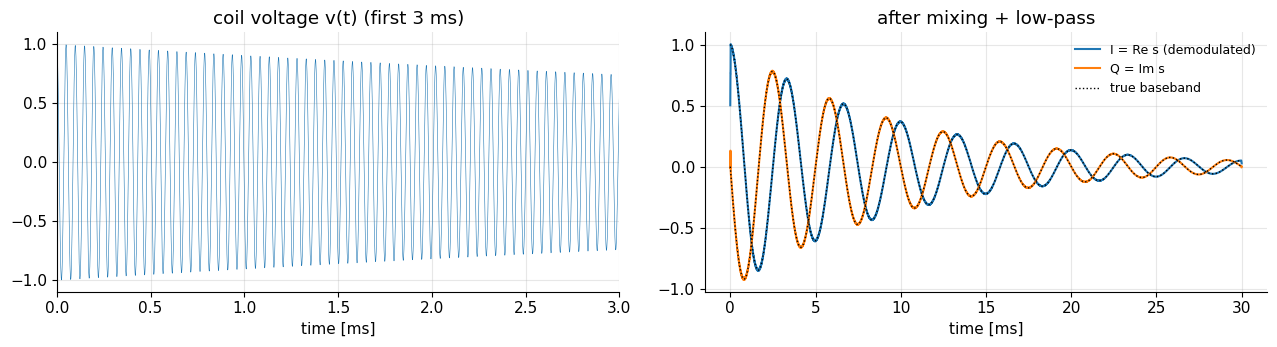

In [2]:
# Quadrature demodulation of a simulated FID (toy carrier frequency)
f_carrier = 20e3                       # Hz (reference = rotating-frame frequency)
df, T2s = 300.0, 10e-3                 # spin off-resonance [Hz], T2* [s]
fs = 1e6; t = np.arange(0, 30e-3, 1/fs)
s_true = np.exp(-1j*2*np.pi*df*t) * np.exp(-t/T2s)                 # baseband (rotating frame) signal
v = np.real(s_true * np.exp(-1j*2*np.pi*f_carrier*t))              # what the coil sees: real RF voltage
mixed = 2 * v * np.exp(+1j*2*np.pi*f_carrier*t)                    # I + iQ channels
L = int(fs / f_carrier)                                            # moving average over 1 carrier period = low-pass
s_demod = np.convolve(mixed, np.ones(L)/L, mode="same")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(t*1e3, v, lw=0.4); ax[0].set_xlim(0, 3); ax[0].set_title("coil voltage v(t) (first 3 ms)"); ax[0].set_xlabel("time [ms]")
ax[1].plot(t*1e3, s_demod.real, label="I = Re s (demodulated)"); ax[1].plot(t*1e3, s_demod.imag, label="Q = Im s")
ax[1].plot(t*1e3, s_true.real, "k:", lw=1, label="true baseband"); ax[1].plot(t*1e3, s_true.imag, "k:", lw=1)
ax[1].set_xlabel("time [ms]"); ax[1].set_title("after mixing + low-pass"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

Interpretation: the 20 kHz oscillation is gone; what remains oscillates at the 300 Hz off-resonance and decays with $T_2^*$, and matches the rotating-frame prediction. The 2f₀ term is removed by the filter (small edge effects at the ends).

> **🔧 Engineering reality:** classic receivers mix in analog stages down to an intermediate frequency; modern ones digitize at (or near) RF with fast ADCs and do the mixing and filtering digitally, avoiding I/Q gain/phase imbalance (which would produce a mirrored "quadrature ghost").

## 2 The image $m(\vec r)$

For simplification we use

$$m(\vec r)=M_{xy}(\vec r,t=TE)$$

In words: the "image" is the transverse magnetization at the echo time TE; all contrast built up until then ($T_1$, $T_2$, proton density…) is contained in it.

and assume the transverse magnetization does not change *during* data acquisition (we add the changes back below). Then we get the simple expression

$$s(t)=\int m(\vec r)\,d\vec r$$

In words: without any encoding, the coil measures one number—the total transverse magnetization.

> **⚠️ Common confusion:** "$t$" in the signal equation is time since excitation, while $m$ is defined at TE. When we add decay as $e^{-t/T_2}$ below, $m$ should strictly be read as $M_{xy}$ right after excitation (or the factor as $e^{-(t-TE)/T_2}$ if $m$ is taken at TE). The difference is only a constant per location; what matters for imaging is the *variation* during the readout window, which is short ($T_{read}\sim$ ms).

## 3 Adding relaxation and off-resonance

The transverse magnetization decays (rotating-frame Bloch equation, [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb): $dM_{xy}/dt=-M_{xy}/T_2$):

$$s(t)=\int m(\vec r)\,e^{-t/T_2(\vec r)}\,d\vec r$$

In words: every location contributes with its own exponentially decaying weight.

Off-resonance and chemical shift change the precession frequency. With $B_{eff,z}=\Delta f/\bar\gamma$ in the rotating frame, the Bloch equation gives $dM_{xy}/dt=-i2\pi\Delta f\,M_{xy}$, i.e. a phase factor $e^{-i2\pi\Delta f t}$ ([A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb)). We define separately:
* $\Delta f_r(\vec r)=\bar\gamma\Delta B_0(\vec r)$ – field inhomogeneities, including main-field imperfections and susceptibility effects,
* $\Delta f_{cs}$ – chemical shift; depends on the chemical species: $0$ for water, $\Delta f_{fat}\approx-3.5$ ppm $\cdot f_0$ for fat.

Combining them into $\Delta f(\vec r)=\Delta f_{cs}+\Delta f_r(\vec r)$:

$$s(t)=\int m(\vec r)\,e^{-i2\pi\Delta f(\vec r)t}\,d\vec r$$

In words: each location's contribution rotates in the complex plane at its own off-resonance frequency; spins at different frequencies get out of phase over time.

When many frequencies exist within one voxel, this dephasing adds to $T_2$ decay and yields the effective $T_2^*$ ($1/T_2^*=1/T_2+1/T_2'$); in a gradient echo, $e^{-t/T_2^*}$ is often used in place of $e^{-t/T_2}$.

## 4 Adding gradients: the signal is a Fourier transform

Gradients also change the precession frequency, but unlike off-resonance they are under our control and vary in time. With a gradient, $B_z(\vec r,t)=B_0+\vec G(t)\cdot\vec r$, so in the rotating frame the extra angular frequency is $\gamma\vec G(t)\cdot\vec r$ and

$$\frac{dM_{xy}}{dt}=-i\gamma\,\vec G(t)\cdot\vec r\;M_{xy}\quad\Longrightarrow\quad M_{xy}(\vec r,t)=m(\vec r)\,e^{i\phi(\vec r,t)},\quad\phi(\vec r,t)=-\gamma\int_0^t\vec G(\tau)\cdot\vec r\,d\tau$$

In words: a time-varying frequency gives a phase equal to (minus) the integral of the angular frequency over time; because the frequency is proportional to position, so is the phase.

(The ODE $dy/dt=-i\omega(t)y$ has solution $y(t)=y(0)\exp(-i\int_0^t\omega(\tau)d\tau)$, see [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb).) Inserting into $s(t)=\int M_{xy}d\vec r$:

$$s(t)=\int m(\vec r)\,\exp\Big(-i\gamma\int_0^t\vec G(\tau)\cdot\vec r\,d\tau\Big)\,d\vec r$$

In words: the gradient waveform imprints a position-dependent phase whose size depends on the cumulative gradient **area** up to time $t$.

Now pull $\vec r$ out of the time integral (it doesn't depend on $\tau$) and write $\gamma=2\pi\bar\gamma$:

$$\gamma\int_0^t\vec G(\tau)\cdot\vec r\,d\tau=2\pi\Big(\bar\gamma\int_0^t\vec G(\tau)d\tau\Big)\cdot\vec r=2\pi\,\vec k(t)\cdot\vec r,\qquad \boxed{\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)\,d\tau}$$

In words: the **k-space position** $\vec k(t)$ is $\bar\gamma$ times the accumulated gradient area; units Hz/T × T/m × s = 1/m (cycles per metre). Example: 10 mT/m for 1 ms gives $k=42.58\times10^6\times10^{-2}\times10^{-3}=426$ m⁻¹.

Therefore

$$s(t)=\int m(\vec r)\,e^{-i2\pi\vec k(t)\cdot\vec r}\,d\vec r=M(\vec k(t)),\qquad M(\vec k)=\mathcal F\{m\}(\vec k)=\int m(\vec r)\,e^{-i2\pi\vec k\cdot\vec r}\,d\vec r$$

In words: the signal at time $t$ *is* the Fourier transform of the image, evaluated at the spatial frequency $\vec k(t)$. By designing $\vec G(t)$ we steer $\vec k(t)$ through "k-space" and collect the Fourier coefficients we need; an inverse Fourier transform then gives the image.

This is the most important equation of MRI image formation. In 1D: $s(t)=\int m(x)e^{-i2\pi k_x(t)x}dx$, the continuous FT of the profile $m(x)$ (compare to the DFT you know: $X[n]=\sum_jx[j]e^{-i2\pi nj/N}$, with $k\leftrightarrow n/FOV$ and $x\leftrightarrow j\,FOV/N$).

> **🔁 Refresher:** continuous vs discrete Fourier transform, units: [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb); shift ↔ linear phase and other properties used below: [RM4](../refreshers/RM4_Fourier_Properties.ipynb); 2D: [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb). Spatial encoding and k-space in depth: [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb), [F2](../pass2_deep_dive/F2_K-space.ipynb).

## 5 Adding RF coil profiles

RF receive coils are not equally sensitive to the whole volume; they have a spatially varying **sensitivity profile**—more sensitive to magnetization near the coil, less to magnetization further away (Section 1.1: $C_n\propto\mathcal B^*_{r,xy}$, the coil's own field pattern, also written $B_1^-$). MRI usually uses many receive elements; coil element $n$ with sensitivity $C_n(\vec r)$ receives

$$s_n(t)=\int m(\vec r)\,C_n(\vec r)\,d\vec r$$

In words: each coil sees the magnetization weighted by its own complex sensitivity map; different coils see different weighted versions of the same object (the basis of parallel imaging, [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

## 6 The complete signal equation

Finally, the most intimidating—and most complete—version, including coil sensitivity, relaxation, off-resonance and chemical shift, and gradients. The signal from coil element $n$ is

$$s_n(t)=\int m(\vec r)\,C_n(\vec r)\,e^{-t/T_2(\vec r)}\,e^{-i2\pi\Delta f_{cs}t}\,e^{-i2\pi\Delta f_r(\vec r)t}\,e^{-i2\pi\vec k(t)\cdot\vec r}\,d\vec r$$

In words: each piece of tissue contributes its transverse magnetization, weighted by the coil's sensitivity, decayed by relaxation, rotated by its off-resonance, and phase-encoded by the gradients; the coil adds everything up.

where all symbols are as defined above and $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ (equivalently $\exp(-i\gamma\int_0^t\vec G\cdot\vec r\,d\tau)$ as in the original).

## 7 Simplified versions

For developing intuition, designing sequences, formulating reconstruction and understanding artifacts we use simplified versions:

**Image formation with only gradients** (neglecting relaxation, coil profile and off-resonance):

$$s(t)=\int m(\vec r)\,e^{-i2\pi\vec k(t)\cdot\vec r}\,d\vec r$$

In words: the ideal case—the signal is exactly the Fourier transform of the image along $\vec k(t)$.

**Relaxation, off-resonance and chemical shift in images** (neglecting gradients and coil volume): after proper spatial encoding and reconstruction, the integration over the volume is effectively removed and the reconstructed image is proportional to

$$s(\vec r,t)\approx m(\vec r)\,e^{-t/T_2(\vec r)}\,e^{-i2\pi\Delta f(\vec r)t}$$

In words: each pixel's value behaves like an isolated spin: it decays and accumulates off-resonance phase with TE. (The original writes this as $s(t)$ without $\vec r$; it is really a per-pixel statement.)

## 8 Numerical experiment: a 1D MRI scanner

We now *simulate* a 1D acquisition by brute-force evaluation of the signal integral (no Fourier assumptions), then reconstruct with an FFT.

**Setup:** FOV = 25.6 cm, $N=128$ readout samples, receiver bandwidth 32 kHz ($\Delta t=31.25$ µs, $T_{read}=4$ ms), readout gradient $G_{x,r}=BW_{read}/(\bar\gamma FOV)$, echo at TE = 10 ms. The k-space position at sample $n$ is $k_n=\bar\gamma G_{x,r}(t_n-TE)=(n-N/2)/FOV$. The object $m(x)$ is defined on a fine grid (4096 points) to mimic a continuous object.

G_read = 2.94 mT/m, dwell = 31.25 us, k_max = 246 1/m, pixel = 2.0 mm, BW/pixel = 250 Hz


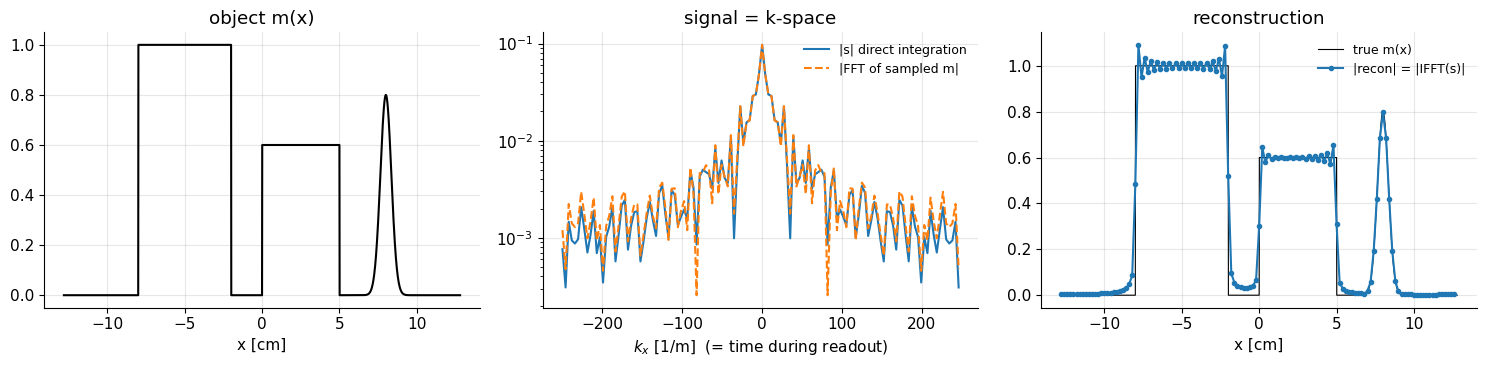

max |recon - m(x_j)| away from edges: 0.01 (median)


In [3]:
# ---- 1D acquisition parameters ----
FOV, N, BW = 0.256, 128, 32e3
dt = 1/BW; TE = 10e-3
G_r = BW / (mt.GAMMA_BAR * FOV)                       # T/m
t_n = TE + (np.arange(N) - N//2) * dt                 # sample times (since excitation)
k_n = mt.GAMMA_BAR * G_r * (t_n - TE)                 # 1/m, equals (n - N/2)/FOV
dk = 1/FOV
x_rec = (np.arange(N) - N//2) * FOV/N                 # reconstruction grid (pixel centres)
print(f"G_read = {G_r*1e3:.2f} mT/m, dwell = {dt*1e6:.2f} us, k_max = {k_n.max():.0f} 1/m, pixel = {FOV/N*1e3:.1f} mm, BW/pixel = {BW/N:.0f} Hz")

# ---- 'continuous' object on a fine grid ----
xf = np.linspace(-FOV/2, FOV/2, 4096, endpoint=False); dxf = xf[1] - xf[0]
m = 1.0*((xf > -0.08) & (xf < -0.02)) + 0.6*((xf > 0.0) & (xf < 0.05)) + 0.8*np.exp(-((xf - 0.08)/0.005)**2)
is_fat = (xf > 0.0) & (xf < 0.05)                     # pretend the middle block is fat (used later)

def acquire(m, T2s=np.inf, df=0.0, C=1.0):
    """Direct evaluation of s(t_n) = sum_x m C exp(-t/T2*) exp(-i2pi df t) exp(-i2pi k x) dx."""
    weight = m * C
    E = np.exp(-1j*2*np.pi*np.outer(k_n, xf))                            # (N, Nx) Fourier kernel
    decay = np.exp(-np.outer(t_n, 1/np.broadcast_to(T2s, xf.shape)))     # (N, Nx)
    offres = np.exp(-1j*2*np.pi*np.outer(t_n, np.broadcast_to(df, xf.shape)))
    return (E * decay * offres) @ weight * dxf

def recon(s):
    """Inverse DFT: m_hat(x_j) = sum_n s_n exp(+i2pi k_n x_j) dk."""
    return mt.ifftc(s, norm="forward") * dk

s = acquire(m)
# FFT prediction: DFT of the object sampled on the reconstruction grid
m_coarse = np.interp(x_rec, xf, m)
s_fft = mt.fftc(m_coarse, norm="backward") * (FOV/N)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(xf*100, m, "k"); ax[0].set_title("object m(x)"); ax[0].set_xlabel("x [cm]")
ax[1].plot(k_n, np.abs(s), label="|s| direct integration"); ax[1].plot(k_n, np.abs(s_fft), "--", label="|FFT of sampled m|")
ax[1].set_yscale("log"); ax[1].set_xlabel(r"$k_x$ [1/m]  (= time during readout)"); ax[1].set_title("signal = k-space"); ax[1].legend(fontsize=9)
ax[2].plot(xf*100, m, "k", lw=0.8, label="true m(x)"); ax[2].plot(x_rec*100, np.abs(recon(s)), "o-", ms=3, label="|recon| = |IFFT(s)|")
ax[2].set_xlabel("x [cm]"); ax[2].set_title("reconstruction"); ax[2].legend(fontsize=9)
plt.tight_layout(); plt.show()
print("max |recon - m(x_j)| away from edges:", np.round(np.median(np.abs(np.abs(recon(s)) - m_coarse)), 4), "(median)")

Interpretation: the signal recorded during the readout is (to plotting accuracy) the FFT of the object—large at $k=0$ (centre of the echo, total magnetization), small at high $|k|$ (edges, fine detail). The inverse FFT reproduces $m(x)$; the small overshoots at sharp edges are Gibbs ringing from truncating k-space at $\pm k_{max}$ ([G3](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb)). The small differences between direct integration and FFT at high $k$ arise because the FFT assumes a sampled (periodic) object, while the direct integral treats it as continuous.

### 8.1 Adding $T_2^*$ decay

During the 4 ms readout the signal also decays. Samples late in the readout (positive $k$) are weaker than early ones: the k-space data are multiplied by $e^{-t_n/T_2^*}$. By the convolution theorem, that multiplies the image by the Fourier transform of the weighting: blurring.

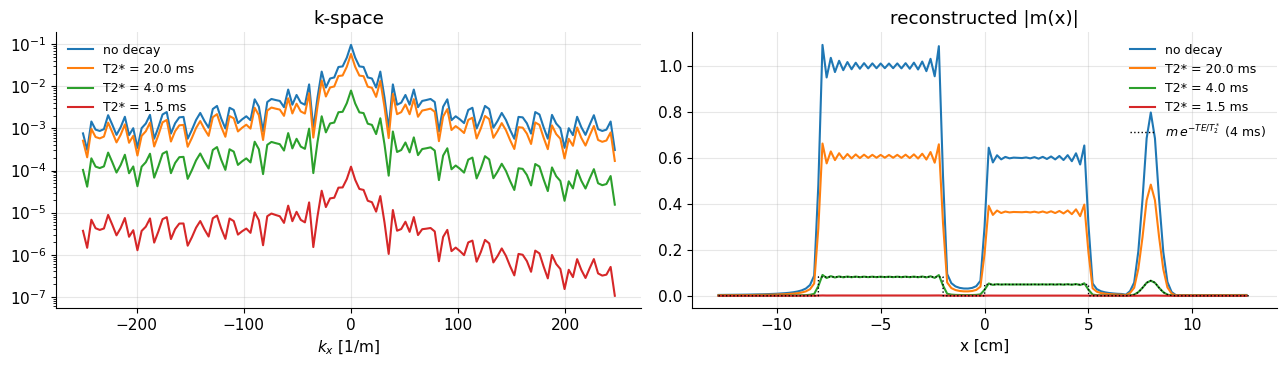

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for T2s in [np.inf, 20e-3, 4e-3, 1.5e-3]:
    s_T = acquire(m, T2s=T2s)
    lab = "no decay" if np.isinf(T2s) else f"T2* = {T2s*1e3:.1f} ms"
    ax[0].plot(k_n, np.abs(s_T), label=lab); ax[1].plot(x_rec*100, np.abs(recon(s_T)), label=lab)
ax[0].set_yscale("log"); ax[0].set_xlabel(r"$k_x$ [1/m]"); ax[0].set_title("k-space"); ax[0].legend(fontsize=9)
ax[1].plot(xf*100, m*np.exp(-TE/4e-3), "k:", lw=1, label=r"$m\,e^{-TE/T_2^*}$ (4 ms)")
ax[1].set_xlabel("x [cm]"); ax[1].set_title("reconstructed |m(x)|"); ax[1].legend(fontsize=9); plt.tight_layout(); plt.show()

Interpretation: shorter $T_2^*$ lowers the overall signal (factor $e^{-TE/T_2^*}$, the $T_2^*$ contrast) and, once $T_2^*$ becomes comparable to $T_{read}$ (4 ms), blurs edges, because high-$k$ samples are attenuated. This is why tissues with very short $T_2^*$ (tendons, bone, lung) need ultrashort-TE methods.

### 8.2 Adding off-resonance: shifts and distortion

Write $t_n=TE+\tau_n$. An off-resonance $\Delta f$ adds the phase $e^{-i2\pi\Delta f\,TE}$ (constant) and $e^{-i2\pi\Delta f\tau_n}$. Since $k_n=\bar\gamma G_{x,r}\tau_n$, the second factor is $e^{-i2\pi k_n\Delta f/(\bar\gamma G_{x,r})}$: a linear phase in k-space, which by the shift theorem ([RM4](../refreshers/RM4_Fourier_Properties.ipynb)) *shifts* the object by

$$\Delta x=\frac{\Delta f}{\bar\gamma G_{x,r}}=\frac{\Delta f}{BW_{read}/N}\ \text{pixels}$$

In words: off-resonant spins are mis-mapped along the readout direction by their frequency offset divided by the bandwidth per pixel.

Below: (a) the middle block is fat at 3 T ($\Delta f_{cs}=-447$ Hz → −1.8 pixels at 250 Hz/pixel); (b) a smooth field inhomogeneity that varies across the object (quadratic, up to 600 Hz) distorts the geometry.

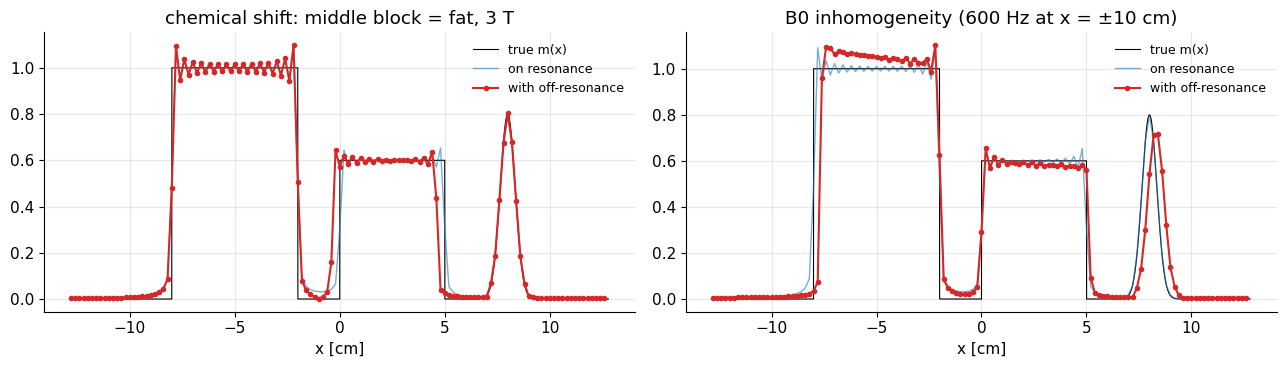

expected fat shift: -1.79 pixels = -3.6 mm


In [5]:
df_fat = np.where(is_fat, mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0), 0.0)            # Hz
df_inhom = 600.0 * (xf / 0.1)**2                                              # Hz, smooth B0 inhomogeneity
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a_, (dfmap, title) in zip(ax, [(df_fat, "chemical shift: middle block = fat, 3 T"), (df_inhom, "B0 inhomogeneity (600 Hz at x = ±10 cm)")]):
    a_.plot(xf*100, m, "k", lw=0.8, label="true m(x)")
    a_.plot(x_rec*100, np.abs(recon(acquire(m))), "C0-", lw=1, alpha=0.6, label="on resonance")
    a_.plot(x_rec*100, np.abs(recon(acquire(m, df=dfmap))), "C3o-", ms=3, label="with off-resonance")
    a_.set_title(title); a_.set_xlabel("x [cm]"); a_.legend(fontsize=9)
plt.tight_layout(); plt.show()
print(f"expected fat shift: {mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)/(BW/N):.2f} pixels = {mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)/(mt.GAMMA_BAR*G_r)*1e3:.1f} mm")

Interpretation: (a) the "fat" block is drawn ~1.8 pixels (3.6 mm) towards negative $x$: a gap appears on one side and an overlap would appear on the other—the chemical-shift artifact. (b) A spatially varying $\Delta f$ shifts different parts by different amounts: the right-hand features are displaced most and the profile is stretched/compressed and its intensity changes (pile-up). Higher readout bandwidth reduces both effects.

### 8.3 Adding coil sensitivities

Two surface coils (loops of radius 8 cm) at $x=\pm15$ cm, with sensitivity taken as their on-axis field profile (`mt.loop_field_on_axis`), each produce a differently weighted image $C_n(x)m(x)$; their root-sum-of-squares combination is more uniform.

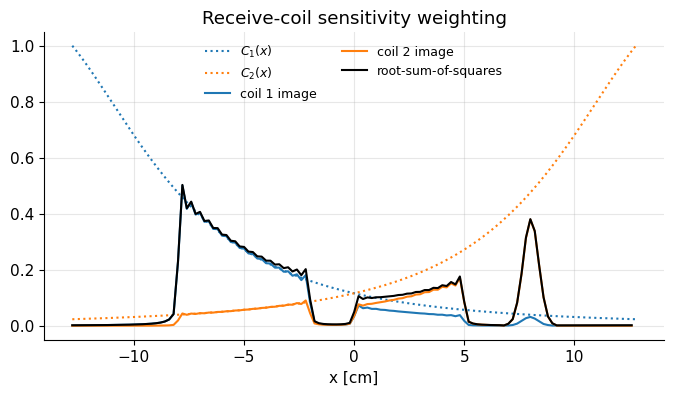

In [6]:
C1 = mt.loop_field_on_axis(xf + 0.15, 0.08, 1.0); C2 = mt.loop_field_on_axis(xf - 0.15, 0.08, 1.0)
C1, C2 = C1/C1.max(), C2/C2.max()
r1, r2 = recon(acquire(m, C=C1)), recon(acquire(m, C=C2))
plt.plot(xf*100, C1, "C0:", label="$C_1(x)$"); plt.plot(xf*100, C2, "C1:", label="$C_2(x)$")
plt.plot(x_rec*100, np.abs(r1), "C0", label="coil 1 image"); plt.plot(x_rec*100, np.abs(r2), "C1", label="coil 2 image")
plt.plot(x_rec*100, np.sqrt(np.abs(r1)**2 + np.abs(r2)**2), "k", label="root-sum-of-squares")
plt.xlabel("x [cm]"); plt.legend(fontsize=9, ncol=2); plt.title("Receive-coil sensitivity weighting"); plt.show()

Interpretation: each coil sees the side nearest to it brightly and the far side weakly; combining coils restores coverage (with residual shading). Knowing $C_n$ explicitly is what allows parallel imaging to skip k-space lines ([H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

> **TODO (polish):** add a 2D version (phase encoding + frequency encoding on `mt.shepp_logan`) and an ipywidgets explorer for BW, $T_2^*$ and $\Delta f$.

## Key takeaways

* The signal is the voltage induced (Faraday) by precessing $M_{xy}$; by reciprocity each location is weighted by the coil's own field pattern $C_n(\vec r)$.
* Quadrature demodulation removes the carrier $e^{-i\omega_0t}$; this is the rotating frame implemented in hardware, so the signal equation is written in the rotating frame.
* Relaxation adds $e^{-t/T_2}$ (or $T_2^*$), off-resonance and chemical shift add $e^{-i2\pi\Delta f(\vec r)t}$.
* Gradients add the phase $-\gamma\int\vec G\cdot\vec r\,d\tau=-2\pi\vec k(t)\cdot\vec r$ with $\vec k(t)=\bar\gamma\int_0^t\vec G\,d\tau$ [1/m].
* Hence $s(t)=\int m(\vec r)e^{-i2\pi\vec k(t)\cdot\vec r}d\vec r=M(\vec k(t))$: **the signal is the Fourier transform of the image** sampled along $\vec k(t)$; an inverse FFT reconstructs it.
* $T_2^*$ decay during readout attenuates late k-space → signal loss and blurring; off-resonance gives a linear phase in k → displacement by $\Delta f/(BW_{read}/N)$ pixels.

## Check your understanding

1. A gradient of 20 mT/m is on for 0.5 ms. What k-space position is reached? What spatial period does that correspond to?

<details><summary>Answer</summary>

$k=42.58\times10^6\times0.02\times0.5\times10^{-3}=426$ m⁻¹; spatial period $1/k=2.35$ mm.

</details>

2. Why does the signal at the centre of the echo ($\vec k=0$) give the total transverse magnetization?

<details><summary>Answer</summary>

At $\vec k=0$ the Fourier kernel $e^{-i2\pi\vec k\cdot\vec r}=1$ everywhere, so $s=\int m(\vec r)d\vec r$: all spins are in phase (that is the gradient echo).

</details>

3. With BW = 32 kHz and 128 samples, how far (pixels, mm for FOV 25.6 cm) is fat shifted at 1.5 T?

<details><summary>Answer</summary>

$|\Delta f|=224$ Hz, BW/pixel $=250$ Hz → 0.9 pixel = 1.8 mm.

</details>

4. Why does the receiver need *two* channels (I and Q) rather than one?

<details><summary>Answer</summary>

One real channel cannot distinguish $+\Delta f$ from $-\Delta f$ (spins above vs below the reference frequency, i.e. left vs right of the centre in the readout direction). Mixing with both $\cos$ and $\sin$ recovers the complex $s(t)$, whose phase rotation direction gives the sign.

</details>

5. In the complete signal equation, which factors depend on position only, which on time only, and which on both?

<details><summary>Answer</summary>

Position only: $m(\vec r)$, $C_n(\vec r)$. Time only: $\vec k(t)$ (but it multiplies $\vec r$). Both: $e^{-t/T_2(\vec r)}$, $e^{-i2\pi\Delta f(\vec r)t}$, $e^{-i2\pi\vec k(t)\cdot\vec r}$. Only the last one is under our control; the others cause the deviations from a pure Fourier transform studied in [I2](../pass2_deep_dive/I2_Artifacts.ipynb).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "MRI Signal Equation". Changes: derivation from Faraday's law and reciprocity, demodulation (with simulation), explicit derivation of the gradient phase and $\vec k(t)$ and of $s(t)=M(\vec k(t))$, clarification of the time origin of $m(\vec r)$ and of the per-pixel simplified equation, and a 1D numerical scanner (direct integration vs FFT, $T_2^*$ blurring, fat shift, $B_0$ distortion, coil sensitivities); typos corrected ("simplifaction", "frequnecy").*